1: Import Libraries & Load Datasets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling set karein
sns.set_theme(style="whitegrid")

# 1. Suggested Dataset: Iris Dataset load karein
df_iris = sns.load_dataset('iris')

# 2. Suggested Dataset: Generated Normal & Skewed Data
np.random.seed(42)
normal_data = np.random.normal(loc=50, scale=10, size=1000)       # Bell-shaped normal data
right_skewed_data = np.random.exponential(scale=10, size=1000)  # Right-skewed data
left_skewed_data = 100 - np.random.exponential(scale=10, size=1000) # Left-skewed data

df_sim = pd.DataFrame({
    'Normal': normal_data,
    'Right_Skewed': right_skewed_data,
    'Left_Skewed': left_skewed_data
})

print("Datasets successfully loaded!")
df_iris.head()

Datasets successfully loaded!


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


2: Statistical Summary (Mean vs Median Check)

In [2]:
def print_summary(df, name):
    print(f"--- Statistical Summary: {name} ---")
    summary = pd.DataFrame({
        'Mean': df.mean(numeric_only=True),
        'Median': df.median(numeric_only=True),
        'Std Dev': df.std(numeric_only=True),
        'Skewness': df.skew(numeric_only=True)
    })
    print(summary)
    print("\n")

print_summary(df_iris, "Iris Dataset")
print_summary(df_sim, "Simulated Distributions")

--- Statistical Summary: Iris Dataset ---
                  Mean  Median   Std Dev  Skewness
sepal_length  5.843333    5.80  0.828066  0.314911
sepal_width   3.057333    3.00  0.435866  0.318966
petal_length  3.758000    4.35  1.765298 -0.274884
petal_width   1.199333    1.30  0.762238 -0.102967


--- Statistical Summary: Simulated Distributions ---
                   Mean     Median    Std Dev  Skewness
Normal        50.193321  50.253006   9.792159  0.116976
Right_Skewed  10.079859   7.259312  10.029885  1.983789
Left_Skewed   90.267480  93.232950   9.453249 -1.637836




3: Histograms for Multiple Variables (Iris Dataset)

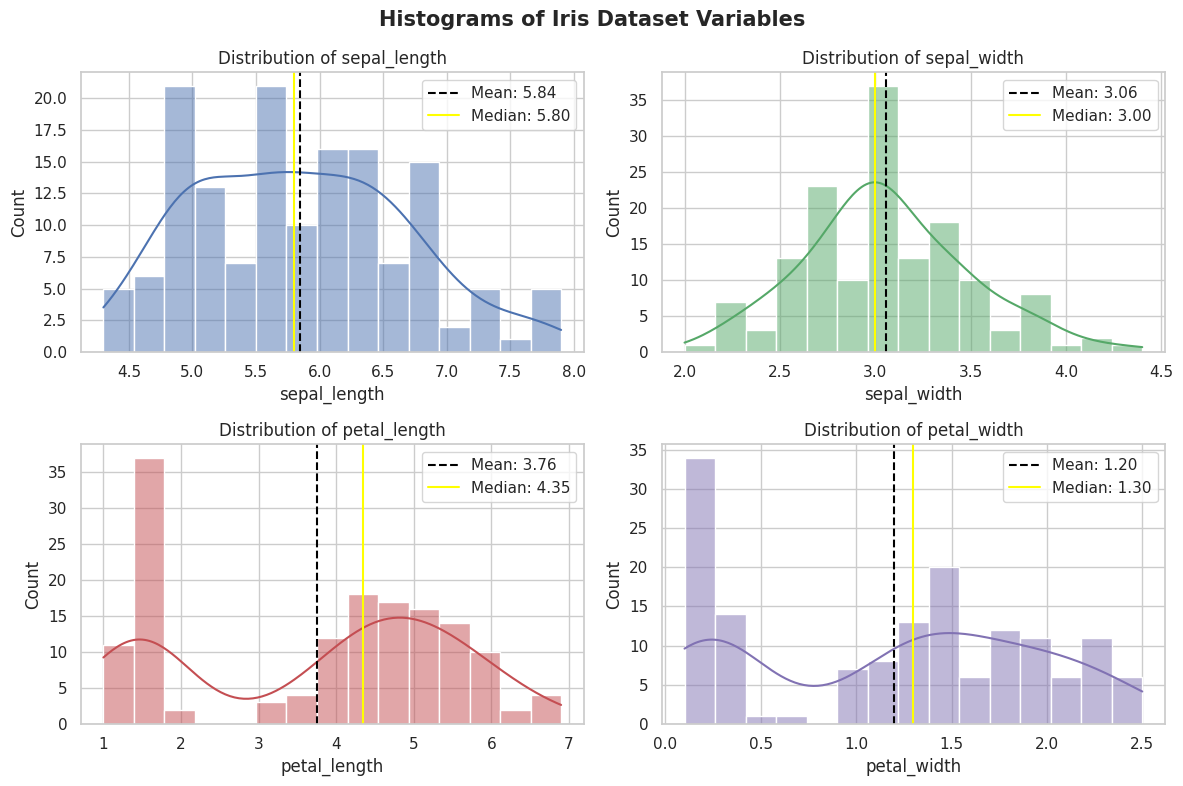

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Histograms of Iris Dataset Variables', fontsize=15, fontweight='bold')

columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B3']

for ax, col, color in zip(axes.flatten(), columns, colors):
    sns.histplot(df_iris[col], kde=True, ax=ax, color=color, bins=15)
    # Mean aur Median lines plot karein
    ax.axvline(df_iris[col].mean(), color='black', linestyle='--', label=f"Mean: {df_iris[col].mean():.2f}")
    ax.axvline(df_iris[col].median(), color='yellow', linestyle='-', label=f"Median: {df_iris[col].median():.2f}")
    ax.set_title(f'Distribution of {col}')
    ax.legend()

plt.tight_layout()
plt.show()

4: Normal vs Skewed Distributions (Simulated Data)

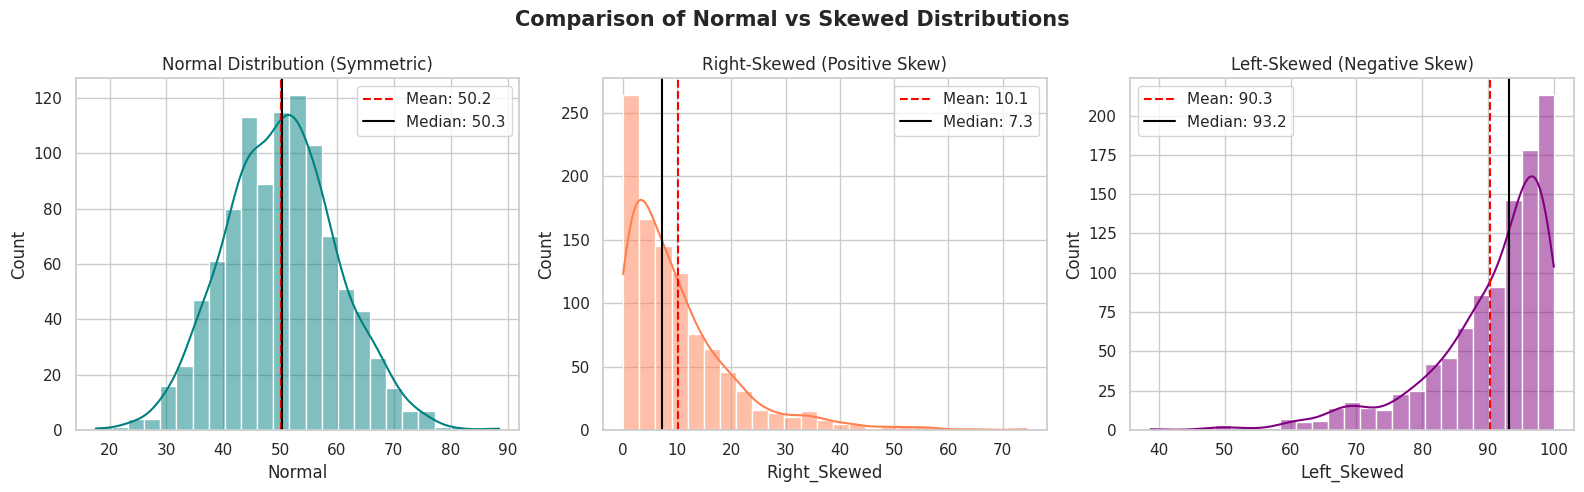

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Comparison of Normal vs Skewed Distributions', fontsize=15, fontweight='bold')

sim_cols = ['Normal', 'Right_Skewed', 'Left_Skewed']
titles = ['Normal Distribution (Symmetric)', 'Right-Skewed (Positive Skew)', 'Left-Skewed (Negative Skew)']
palette = ['teal', 'coral', 'purple']

for ax, col, title, color in zip(axes, sim_cols, titles, palette):
    sns.histplot(df_sim[col], kde=True, ax=ax, color=color, bins=25)
    ax.axvline(df_sim[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df_sim[col].mean():.1f}")
    ax.axvline(df_sim[col].median(), color='black', linestyle='-', linewidth=1.5, label=f"Median: {df_sim[col].median():.1f}")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()